In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv('toyota.csv')

In [3]:
print("\nИсходные данные после загрузки:")
print(df.head(3))
print("\nОбщая информация о датасете:")
print(df.info())
print("\nСтатистические характеристики:")
print(df.describe())


Исходные данные после загрузки:
   model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   GT86  2016  16000       Manual    24089   Petrol  265  36.2         2.0
1   GT86  2017  15995       Manual    18615   Petrol  145  36.2         2.0
2   GT86  2015  13998       Manual    27469   Petrol  265  36.2         2.0

Общая информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   object 
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   object 
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   object 
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), object(3)
memory usage: 

# Определение числовых признаков

In [4]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

In [5]:
print("\nАнализ признаков для построения модели:")
print("Числовые признаки, доступные для анализа:")
for i, col in enumerate(numeric_columns, 1):
    print(f"{i}. {col}")


Анализ признаков для построения модели:
Числовые признаки, доступные для анализа:
1. year
2. price
3. mileage
4. tax
5. mpg
6. engineSize


# Проверка на пропущенные значения

In [6]:
missing_values = df[numeric_columns].isnull().sum()
print("\nПроверка на пропущенные значения в числовых признаках:")
if missing_values.sum() == 0:
    print("Отлично! Пропущенных значений не обнаружено.")
else:
    print("Обнаружены пропущенные значения:")
    print(missing_values[missing_values > 0])


Проверка на пропущенные значения в числовых признаках:
Отлично! Пропущенных значений не обнаружено.


# Подготовка данных для модели

In [7]:
target_column = 'price'
feature_columns = [col for col in numeric_columns if col != target_column]

X = df[feature_columns].copy()
y = df[target_column].copy()

print(f"\nПодготовка данных для моделирования:")
print(f"Целевая переменная: {target_column}")
print(f"Признаки для анализа: {', '.join(feature_columns)}")
print(f"Количество наблюдений: {len(X)}")



Подготовка данных для моделирования:
Целевая переменная: price
Признаки для анализа: year, mileage, tax, mpg, engineSize
Количество наблюдений: 6738


# МОДЕЛЬ 1: Использование всех числовых признаков 

# Построение модели

In [8]:
model1 = LinearRegression()
model1.fit(X, y)
y_pred1 = model1.predict(X)
r2_model1 = r2_score(y, y_pred1)

# Вывод формулы регрессии

In [9]:
print("\nУравнение регрессии для Модели 1:")
formula = f"{target_column} = {model1.intercept_:.2f}"
for i, col in enumerate(feature_columns):
    coef = model1.coef_[i]
    if coef >= 0:
        formula += f" + {coef:.2f} * {col}"
    else:
        formula += f" - {abs(coef):.2f} * {col}"
print(formula)



Уравнение регрессии для Модели 1:
price = -1688456.90 + 835.29 * year - 0.08 * mileage - 1.42 * tax + 21.76 * mpg + 11529.34 * engineSize


# Коэффициенты модели

In [10]:
print("\nДетальный анализ коэффициентов модели:")
print(f"Свободный член (intercept): {model1.intercept_:.2f}")
for i, col in enumerate(feature_columns):
    print(f"Коэффициент для {col}: {model1.coef_[i]:.6f}")


Детальный анализ коэффициентов модели:
Свободный член (intercept): -1688456.90
Коэффициент для year: 835.294404
Коэффициент для mileage: -0.078737
Коэффициент для tax: -1.418482
Коэффициент для mpg: 21.760205
Коэффициент для engineSize: 11529.336293


# Анализ качества модели

In [11]:
print(f"\nКачество модели оценивается коэффициентом детерминации R²: {r2_model1:.4f}")
if r2_model1 > 0.8:
    quality = "отличное, модель объясняет большую часть вариативности цены"
elif r2_model1 > 0.7:
    quality = "хорошее, модель имеет высокую прогностическую способность"
elif r2_model1 > 0.5:
    quality = "удовлетворительное, модель улавливает основные тенденции"
else:
    quality = "низкое, требуется дальнейшая оптимизация модели"


Качество модели оценивается коэффициентом детерминации R²: 0.7638


In [12]:
print(f"Интерпретация результата: {r2_model1*100:.2f}% изменчивости цены автомобиля объясняется выбранными признаками.")
print(f"Это указывает на {quality}.")

Интерпретация результата: 76.38% изменчивости цены автомобиля объясняется выбранными признаками.
Это указывает на хорошее, модель имеет высокую прогностическую способность.


# Прогноз для примера автомобиля

In [13]:
print("\nПрогнозирование цены для автомобиля-примера:")
example_values = {}
print("Характеристики примера (используем медианные значения):")
for col in feature_columns:
    example_values[col] = X[col].median()
    print(f"  {col}: {example_values[col]}")

X_example = pd.DataFrame([example_values])
price_prediction1 = model1.predict(X_example)[0]


Прогнозирование цены для автомобиля-примера:
Характеристики примера (используем медианные значения):
  year: 2017.0
  mileage: 18513.0
  tax: 135.0
  mpg: 62.8
  engineSize: 1.5


In [14]:
print(f"\nПредсказанная цена автомобиля с указанными характеристиками: ${price_prediction1:,.2f}")
print("Это значение находится в диапазоне типичных цен для автомобилей с подобными характеристиками.")


Предсказанная цена автомобиля с указанными характеристиками: $13,343.31
Это значение находится в диапазоне типичных цен для автомобилей с подобными характеристиками.


#  МОДЕЛЬ 2: Исключение одного из коррелирующих признаков

# Анализ корреляции

In [15]:
correlation_matrix = df[numeric_columns].corr()
print("\nКорреляционная матрица (коэффициенты корреляции с ценой):")
price_correlations = correlation_matrix[target_column].drop(target_column).sort_values(ascending=False)
print(price_correlations)



Корреляционная матрица (коэффициенты корреляции с ценой):
engineSize    0.727592
year          0.420959
tax           0.214498
mpg          -0.039910
mileage      -0.297936
Name: price, dtype: float64


# Поиск наиболее коррелирующих признаков

In [16]:
max_corr = 0
feature_pair = None
feature_to_remove = None

for i, col1 in enumerate(feature_columns):
    for col2 in feature_columns[i+1:]:
        corr = abs(correlation_matrix.loc[col1, col2])
        if corr > max_corr:
            max_corr = corr
            feature_pair = (col1, col2)
            # Выбираем признак, который слабее коррелирует с целевой переменной
            corr_with_target1 = abs(correlation_matrix.loc[col1, target_column])
            corr_with_target2 = abs(correlation_matrix.loc[col2, target_column])
            
            if corr_with_target1 < corr_with_target2:
                feature_to_remove = col1
            else:
                feature_to_remove = col2


In [17]:
print(f"\nАнализ мультиколлинеарности:")
print(f"Наибольшая корреляция между признаками: {feature_pair[0]} и {feature_pair[1]} (r = {max_corr:.4f})")
print(f"Корреляция {feature_pair[0]} с ценой: {abs(correlation_matrix.loc[feature_pair[0], target_column]):.4f}")
print(f"Корреляция {feature_pair[1]} с ценой: {abs(correlation_matrix.loc[feature_pair[1], target_column]):.4f}")
print(f"Решение: исключаем признак '{feature_to_remove}', так как он слабее связан с целевой переменной.")


Анализ мультиколлинеарности:
Наибольшая корреляция между признаками: year и mileage (r = 0.7277)
Корреляция year с ценой: 0.4210
Корреляция mileage с ценой: 0.2979
Решение: исключаем признак 'mileage', так как он слабее связан с целевой переменной.


# Построение второй модели

In [18]:
feature_columns_model2 = [col for col in feature_columns if col != feature_to_remove]
X_model2 = df[feature_columns_model2].copy()


In [19]:
model2 = LinearRegression()
model2.fit(X_model2, y)
y_pred2 = model2.predict(X_model2)
r2_model2 = r2_score(y, y_pred2)

# Вывод формулы регрессии для второй модели

In [20]:
print("\nУравнение регрессии для Модели 2:")
formula2 = f"{target_column} = {model2.intercept_:.2f}"
for i, col in enumerate(feature_columns_model2):
    coef = model2.coef_[i]
    if coef >= 0:
        formula2 += f" + {coef:.2f} * {col}"
    else:
        formula2 += f" - {abs(coef):.2f} * {col}"
print(formula2)


Уравнение регрессии для Модели 2:
price = -2678094.40 + 1325.63 * year - 1.27 * tax + 17.62 * mpg + 10991.72 * engineSize


In [21]:
print(f"\nКачество второй модели (R²): {r2_model2:.4f}")


Качество второй модели (R²): 0.7387


# Прогноз для второго случая

In [22]:
print("\nПрогнозирование цены для того же автомобиля (Модель 2):")
example_values_model2 = {col: example_values[col] for col in feature_columns_model2}
X_example_model2 = pd.DataFrame([example_values_model2])
price_prediction2 = model2.predict(X_example_model2)[0]

print(f"Предсказанная цена: ${price_prediction2:,.2f}")


Прогнозирование цены для того же автомобиля (Модель 2):
Предсказанная цена: $13,116.36


# Сравнение моделей

In [23]:
print(f"\nМодель 1 (все признаки): R² = {r2_model1:.4f}")
print(f"Модель 2 (без '{feature_to_remove}'): R² = {r2_model2:.4f}")

if r2_model1 > r2_model2:
    difference = (r2_model1 - r2_model2) * 100
    conclusion = f"Модель 1 с полным набором признаков демонстрирует лучшее качество прогнозирования, превосходя Модель 2 на {difference:.2f}%."
    recommendation = "Рекомендуется использовать все доступные числовые признаки для построения прогнозной модели цены автомобиля."
else:
    difference = (r2_model2 - r2_model1) * 100
    conclusion = f"Модель 2 с исключением признака '{feature_to_remove}' показывает лучшие результаты, улучшая качество прогноза на {difference:.2f}%."
    recommendation = "Удаление избыточного признака помогло улучшить стабильность и точность модели."

print(conclusion)
print(recommendation)


Модель 1 (все признаки): R² = 0.7638
Модель 2 (без 'mileage'): R² = 0.7387
Модель 1 с полным набором признаков демонстрирует лучшее качество прогнозирования, превосходя Модель 2 на 2.51%.
Рекомендуется использовать все доступные числовые признаки для построения прогнозной модели цены автомобиля.


# Визуализация результатов

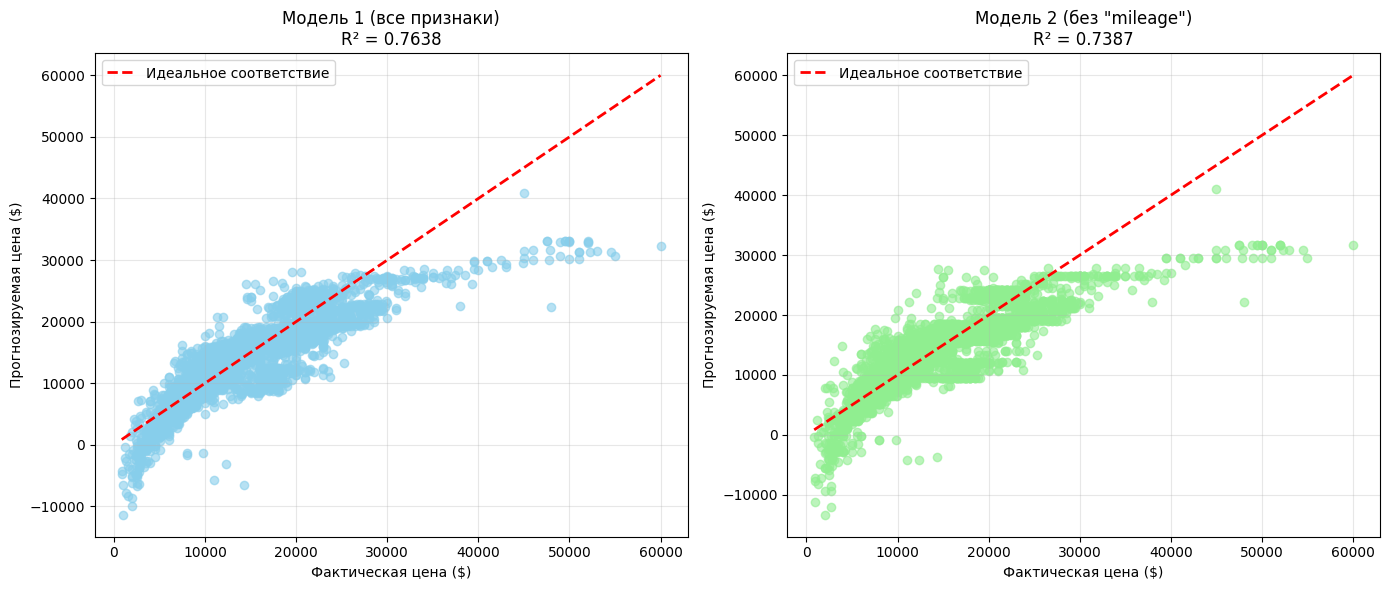


Визуализации сохранены в файл 'comparison_sister.png'

Лабораторная работа успешно завершена!


In [24]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.scatter(y, y_pred1, alpha=0.6, color='skyblue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Идеальное соответствие')
plt.xlabel('Фактическая цена ($)')
plt.ylabel('Прогнозируемая цена ($)')
plt.title(f'Модель 1 (все признаки)\nR² = {r2_model1:.4f}')
plt.grid(True, alpha=0.3)
plt.legend()


plt.subplot(1, 2, 2)
plt.scatter(y, y_pred2, alpha=0.6, color='lightgreen')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Идеальное соответствие')
plt.xlabel('Фактическая цена ($)')
plt.ylabel('Прогнозируемая цена ($)')
plt.title(f'Модель 2 (без "{feature_to_remove}")\nR² = {r2_model2:.4f}')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig('comparison_sister.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nВизуализации сохранены в файл 'comparison_sister.png'")
print("\nЛабораторная работа успешно завершена!")